# Cleaning and structural-unit review

Scope: the first-pass pages (`data/pages.jsonl`, 76) and the core legal set (`data/text/legal/`, 110 with text).
Questions answered here: **(1)** did extraction keep the source content? **(2)** what did cleaning change? **(3)** do the FAQ and statute boundaries hold?
**(4)** how long are documents and units (input to the later chunk-size decision; token counts deferred)?

Re-run: `uv run python -m crawler.clean.build` then `uv run jupyter nbconvert --to notebook --execute --inplace notebooks/clean_review.ipynb`.
Section 1 needs `data/raw` (not committed); the stored outputs are the snapshot.

In [1]:
import csv, json, os, re
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "pages.jsonl").exists())
os.chdir(ROOT)
from crawler.clean.audit import legal_coverage, page_coverage
from crawler.clean.text import normalize

BLUE, GRAY = "#2b6cb0", "#8a8f98"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "axes.axisbelow": True, "figure.dpi": 110, "font.size": 9})
pd.set_option("display.max_colwidth", 80, "display.width", 160)
docs = pd.DataFrame(json.loads(l) for l in open("data/clean/documents.jsonl", encoding="utf-8"))
units = pd.DataFrame(json.loads(l) for l in open("data/clean/units.jsonl", encoding="utf-8"))
docs["n_units"].sum(), len(docs), len(units)

(np.int64(668), 186, 668)

## 0. What is in the clean corpus

In [2]:
t = docs.groupby(["source", "kind", "role"]).agg(docs=("doc_id", "count"), included=("include", "sum"), median_chars=("n_chars", "median"), max_chars=("n_chars", "max"))
t

docs  included  median_chars  max_chars
source kind                 role                                            
legal  กฎกระทรวง            content    23        23        2450.0      61309
       คำวินิจฉัย           content    10        10        2657.5       4507
       คำสั่งกรมสรรพากร     content    20        20        7280.0      20653
       ประกาศกรมสรรพากร     content     2         2        2074.0       2725
       ประกาศกระทรวงการคลัง content     4         4        2098.5       4039
       ประกาศอธิบดี         content    32        32        3701.5      19479
       พระราชกฤษฎีกา        content    19        19        3553.0      31756
page   article              content    32        32        1671.0      14829
                            hub        11         0         208.0        380
                            thin        2         0         144.0        170
       faq                  content    18        18       10283.0      52646
       index                content     1         1        2886.0       2886
       ruling               content    10        10        3189.5       7558
       statute              content     1         1       65105.0      65105
                            toc         1         0        3157.0       3157

## 1. Extraction coverage (before any cleaning)

Compared with the raw source: **character recall** (multiset of non-space characters) and **number recall** (amounts and rates).
Pages: against the visible text of `col-main`. Legal HTML/PDF: against the raw HTML or `pdftotext`. **OCR documents (11) cannot be compared this way**
(their text layer is garbage); they are checked structurally in section 4 and need a manual spot-check.

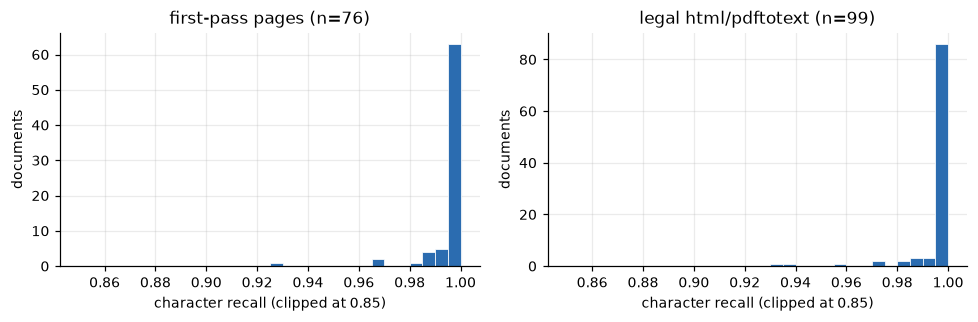

pages: median recall 1.000; <0.95: 1; docs with a missing non-link fragment: 14
legal: median recall 1.000; <0.98: 5; min 0.934


In [3]:
pc = pd.DataFrame(page_coverage(Path("data/pages.jsonl"), Path("data/raw")))
lc = pd.DataFrame(legal_coverage(list(csv.DictReader(open("data/legal_text.csv", encoding="utf-8"))), Path("data")))
fig, ax = plt.subplots(1, 2, figsize=(9, 3), sharey=False)
for a, df, title in ((ax[0], pc, f"first-pass pages (n={len(pc)})"), (ax[1], lc, f"legal html/pdftotext (n={len(lc)})")):
    a.hist(df.char_recall.clip(.85, 1), bins=30, range=(.85, 1), color=BLUE, edgecolor="white", linewidth=.5)
    a.set_title(title); a.set_xlabel("character recall (clipped at 0.85)"); a.set_ylabel("documents")
plt.tight_layout(); plt.show()
print(f"pages: median recall {pc.char_recall.median():.3f}; <0.95: {(pc.char_recall<.95).sum()}; docs with a missing non-link fragment: {(pc.missing_fragments.str.len()>0).sum()}")
print(f"legal: median recall {lc.char_recall.median():.3f}; <0.98: {(lc.char_recall<.98).sum()}; min {lc.char_recall.min():.3f}")

**Pages: fragments present in the source main column but missing from the text** (anchor text of body links excluded).
Most are page chrome ("Untitled Document", visitor counter, call-centre blurb). The one real content loss was `60061` (the last paragraph of item 4, a bare `<strong>` outside any `<p>`, dropped by trafilatura);
it is fixed in `parse._wrap_bare_inline` and the table below no longer lists it as lost.

In [4]:
m = pc[pc.missing_fragments.str.len() > 0][["doc_id", "char_recall", "missing_fragments"]].copy()
m["first_missing"] = m.missing_fragments.str[0].str.slice(0, 90); m["n"] = m.missing_fragments.str.len()
m.drop(columns="missing_fragments").sort_values("char_recall")

,doc_id,char_recall,first_missing,n
54,59670,0.926952,RD Intelligence Center,2
53,59668,0.983553, ในกรณีผู้มีเงินได้มีบุตรชอบด้วยกฎหมายที่มีชีวิตอยู่รวมเป็นจำนวนตั้งแต่ 3 ค...,4
47,5938,0.985587,บัญชีอัตราภาษีเงินได้,1
57,60054,0.989684,Untitled Document,1
65,28933,0.991929,RD Call Center 1161,3
49,63437,0.996753,จำนวนผู้เยี่ยมชม,1
73,61117,0.998398,Untitled Document,2
50,63908,0.998418,จำนวนผู้เยี่ยมชม,1
48,61081,0.999011,A3 : ไม่สามารถแก้ไขรายการที่ลงทะเบียนได้ แต่หากมีการเปลี่ยนแปลง เช่น เปลี่ยน...,2
72,61065,0.999012,Untitled Document,2


**Legal: lines whose numbers are not in the cached text.** Expected: only Royal Gazette running headers (`เล่ม … ตอน …`, `หน้า …`), which extraction strips on purpose and which the audit already ignores.
An empty table means no numeric content was lost.

In [5]:
lost = lc[lc.lost_number_lines.str.len() > 0][["doc_id", "method", "number_recall", "lost_number_lines"]]
lost if len(lost) else "no legal HTML/pdftotext document lost a numeric line apart from Gazette headers"

'no legal HTML/pdftotext document lost a numeric line apart from Gazette headers'

## 2. What cleaning changes

`normalize()` is character- and whitespace-level only. Counts below are over the corpora **before** cleaning, then after.

In [6]:
pages_raw = [json.loads(l)["text"] or "" for l in open("data/pages.jsonl", encoding="utf-8")]
legal_raw = [Path("data/text/legal", r["file"]).read_text(encoding="utf-8") for r in csv.DictReader(open("data/legal_text.csv", encoding="utf-8")) if r["status"] == "ok"]
checks = {
    "cp1252 control chars (\\x80-\\x9f)": r"[\x80-\x9f]", "no-break space": "\xa0", "zero-width chars": "[\u200b-\u200d\ufeff]",
    "runs of spaces/tabs": r"[ \t]{2,}", "Thai digits": "[๐-๙]", "leaked <br>": r"<br\s*/?>", "HTML entities": r"&[a-z]+;",
    "split sara am": "\u0e4d\u0e32", "trailing whitespace": r"[ \t]+$",
}
rows = []
for name, pat in checks.items():
    f = lambda texts: sum(bool(re.search(pat, t, re.M)) for t in texts)
    rows.append({"issue": name, "pages before": f(pages_raw), "pages after": f(map(normalize, pages_raw)),
                 "legal before": f(legal_raw), "legal after": f(map(normalize, legal_raw))})
pd.DataFrame(rows)

,issue,pages before,pages after,legal before,legal after
0,cp1252 control chars (\x80-\x9f),0,0,38,0
1,no-break space,36,0,0,0
2,zero-width chars,0,0,0,0
3,runs of spaces/tabs,29,0,0,0
4,Thai digits,1,0,0,0
5,leaked <br>,1,0,0,0
6,HTML entities,0,0,2,0
7,split sara am,1,0,0,0
8,trailing whitespace,43,0,0,0


**Royal Gazette page furniture in PDF-derived legal text** (28 documents: 17 pdftotext, 11 OCR).

In [7]:
from crawler.clean.gazette import NUMBERING, PAGE, DATE, strip_page_headers
rows = []
for r in csv.DictReader(open("data/legal_text.csv", encoding="utf-8")):
    if r["status"] != "ok" or r["method"] not in ("pdftotext", "ocr"):
        continue
    t = normalize(Path("data/text/legal", r["file"]).read_text(encoding="utf-8"))
    out, gdate, removed = strip_page_headers(t)
    lines = [l.strip() for l in t.split("\n")]
    rows.append({"file": r["url"].rsplit("/", 1)[-1], "method": r["method"],
                 "header lines before": sum(bool(NUMBERING.match(l) or PAGE.match(l)) for l in lines),
                 "standalone dates before": sum(bool(DATE.match(l)) for l in lines),
                 "removed": len(removed), "gazette_date": gdate or ""})
g = pd.DataFrame(rows)
print(f"{len(g)} PDF-derived documents; {(g.removed > 0).sum()} had page-header lines removed ({g.removed.sum()} lines); publication date found in {(g.gazette_date != '').sum()}")
g[g.removed > 0].sort_values("removed", ascending=False)

28 PDF-derived documents; 17 had page-header lines removed (46 lines); publication date found in 21


,file,method,header lines before,standalone dates before,removed,gazette_date
2,mr386.PDF,pdftotext,3,3,5,29 ธันวาคม 2565
20,dg357.pdf,pdftotext,3,3,5,18 ธันวาคม 2562
5,mr388.pdf,pdftotext,3,3,5,3 มีนาคม 2566
25,dc629.pdf,pdftotext,0,5,4,27 มกราคม 2560
19,dg346.pdf,pdftotext,2,2,3,24 พฤษภาคม 2562
4,mr387.pdf,pdftotext,2,2,3,3 กุมภาพันธ์ 2566
10,mr396.pdf,ocr,1,3,3,20 ธันวาคม 2567
3,mr385.pdf,pdftotext,2,2,3,25 พฤศจิกายน 2565
1,mr350.pdf,pdftotext,2,2,3,25 มิถุนายน 2562
27,dc664.pdf,pdftotext,0,3,2,22 พฤศจิกายน 2561


Deliberately **not** done yet (needs the instrument/ruling/article splitters): unwrapping hard-wrapped PDF/OCR lines (~50 chars/line),
restoring paragraphs in flattened HTML legal text (up to ~1,460 chars/line), stripping OCR `**bold**`.
Quote style is also left as found: the source mixes “ ”, `"` and sometimes closes a quote with “ (e.g. `13481.html`).
Done for PDF-derived legal text (`crawler.clean.gazette`): Gazette page headers that extraction missed (`เลม่ … ตอน …` from pdftotext's out-of-order tone mark, and OCR's `หน้า N ราชกิจจานุเบกษา`) are removed, the publication date repeated at every page start is kept once and stored as `gazette_date`. Typhoon OCR writes ASCII digits whatever the print form (0 Thai digits in the 11 OCR files), so `normalize` has nothing to do there.


## 3. Length distributions (input to the chunk-size decision; tokens come later)

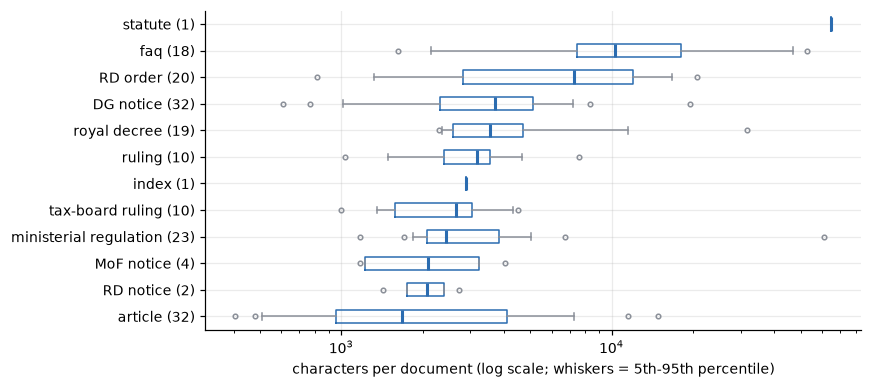

,count,mean,std,min,50%,90%,max
kind,,,,,,,
article,32.0,3083.0,3290.0,405.0,1671.0,6803.0,14829.0
faq,18.0,16204.0,15131.0,1622.0,10283.0,42711.0,52646.0
index,1.0,2886.0,NaN,2886.0,2886.0,2886.0,2886.0
ruling,10.0,3303.0,1831.0,1029.0,3190.0,4967.0,7558.0
statute,1.0,65105.0,NaN,65105.0,65105.0,65105.0,65105.0
กฎกระทรวง,23.0,5486.0,12233.0,1174.0,2450.0,4900.0,61309.0
คำวินิจฉัย,10.0,2606.0,1200.0,996.0,2658.0,4351.0,4507.0
คำสั่งกรมสรรพากร,20.0,7879.0,6118.0,810.0,7280.0,15889.0,20653.0
ประกาศกรมสรรพากร,2.0,2074.0,921.0,1423.0,2074.0,2595.0,2725.0


In [8]:
# no Thai font on this machine, so plot labels use English names; tables keep the Thai kind
KIND_EN = {"กฎกระทรวง": "ministerial regulation", "คำวินิจฉัย": "tax-board ruling", "คำสั่งกรมสรรพากร": "RD order", "ประกาศกรมสรรพากร": "RD notice",
           "ประกาศกระทรวงการคลัง": "MoF notice", "ประกาศอธิบดี": "DG notice", "พระราชกฤษฎีกา": "royal decree"}
inc = docs[docs.include]
order = inc.groupby("kind").n_chars.median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([inc[inc.kind == k].n_chars for k in order], orientation="horizontal", tick_labels=[f"{KIND_EN.get(k, k)} ({(inc.kind==k).sum()})" for k in order], whis=(5, 95),
           boxprops=dict(color=BLUE), medianprops=dict(color=BLUE, lw=2), whiskerprops=dict(color=GRAY), capprops=dict(color=GRAY), flierprops=dict(marker=".", mec=GRAY))
ax.set_xscale("log"); ax.set_xlabel("characters per document (log scale; whiskers = 5th-95th percentile)")
plt.tight_layout(); plt.show()
inc.groupby("kind").n_chars.describe(percentiles=[.5, .9]).round(0)

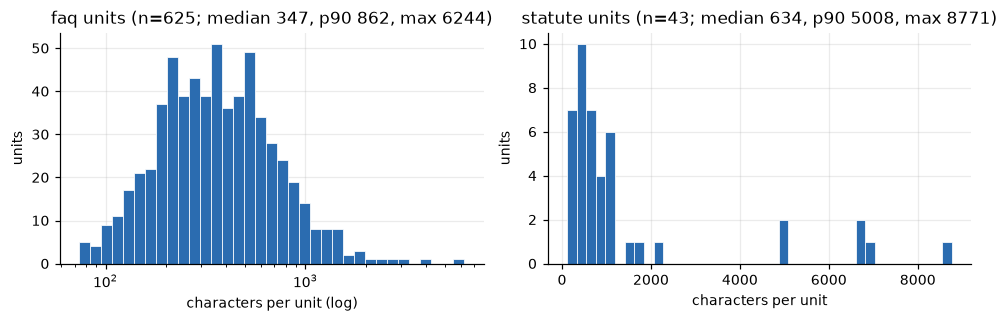

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for a, typ in zip(ax, ("faq", "statute")):
    s = units[units.type == typ].text.str.len()
    import numpy as np
    a.hist(s, bins=np.logspace(np.log10(s.min()), np.log10(s.max()), 36) if typ == "faq" else 40, color=BLUE, edgecolor="white", linewidth=.5)
    a.set_xscale("log") if typ == "faq" else None
    a.set_title(f"{typ} units (n={len(s)}; median {int(s.median())}, p90 {int(s.quantile(.9))}, max {s.max()})")
    a.set_xlabel("characters per unit" + (" (log)" if typ == "faq" else "")); a.set_ylabel("units")
plt.tight_layout(); plt.show()

## 4. Unit boundaries

### 4a. FAQ: items per page and flags

`marker_q_lost` = a `Q` dropped by extraction, recognised from the number sequence. `title_inherited` = a second question under one title.
`section_guessed` = unnumbered section heading taken from the last short line of the previous answer (**reviewed below**).

In [10]:
f = units[units.type == "faq"].copy()
f["flags_s"] = f["flags"].str.join(",")
pg = f.groupby("doc_id").agg(items=("unit_id", "count"), sections=("section", lambda s: s.dropna().nunique()),
                              flags=("flags_s", lambda s: dict(Counter(x for v in s for x in v.split(",") if x))))
pg.join(docs.set_index("doc_id")[["title", "tax_year"]]).assign(title=lambda d: d.title.str.slice(0, 45))

,items,sections,flags,title,tax_year
doc_id,,,,,
60054,4,0,{},หมวดค่าลดหย่อนส่วนตัวและคู่สมรส,2560.0
60055,11,0,{},หมวดค่าลดหย่อนบุตร,2560.0
60056,14,0,{},หมวดค่าลดหย่อนอุปการะเลี้ยงดูบิดา/มารดา,2560.0
60057,8,0,{'title_inherited': 1},หมวดค่าลดหย่อนอุปการะเลี้ยงดูคนพิการ/ทุพลภาพ,2560.0
60058,14,0,{},หมวดค่าลดหย่อนประกันชีวิต/ประกันชีวิตแบบบำนาญ,2560.0
60059,13,0,{'title_inherited': 3},หมวดค่าลดหย่อนซื้อหน่วยลงทุน RMF และ LTF,2560.0
60060,16,0,{},หมวดค่าลดหย่อนดอกเบี้ยเงินกู้ยืมเพื่อซื้อ/สร้,2560.0
60061,4,0,{},หมวดค่าลดหย่อนประกันสังคม,2560.0
60062,11,0,{},หมวดค่าลดหย่อนเงินบริจาค,2560.0


**Section headings guessed on the two pages with unnumbered headings** (`62149`, `62777`). Check each against the page; a wrong guess leaves one short line in the wrong place, never loses text.

In [11]:
g = f[f.flags_s.str.contains("section_guessed")][["doc_id", "unit_id", "label", "section"]]
g.reset_index(drop=True)

,doc_id,unit_id,label,section
0,62149,62149#006,Q1,ประเภทเงินได้
1,62149,62149#014,Q1,การหักค่าใช้จ่าย
2,62149,62149#025,Q1,การหักค่าลดหย่อน
3,62149,62149#058,Q1,การคำนวณภาษี
4,62149,62149#060,Q1,การยื่นแบบฯ และชำระภาษี
5,62149,62149#069,Q1,การขอคืนภาษี
6,62149,62149#074,Q1,บทลงโทษ
7,62777,62777#004,Q1,คู่สมรส
8,62777,62777#006,Q1,บุตร
9,62777,62777#015,Q1,ค่าฝากครรภ์และค่าคลอดบุตร


### 4b. Statute (ม.38–64): sections, notes, repeals

In [12]:
s = units[units.type == "statute"].copy()
s["chars"] = s.text.str.len()
s["see"] = s.notes.apply(lambda n: sum(x["type"] == "see" for x in n))
s["amendment"] = s.notes.apply(lambda n: sum(x["type"] == "amendment" for x in n))
s["repeal"] = s.notes.apply(lambda n: sum(x["type"] == "repeal" for x in n))
print(f"{len(s)} sections; notes: see {s.see.sum()}, amendment {s.amendment.sum()}, repeal {s.repeal.sum()}")
print("sections carrying a repeal note (text may describe repealed law):", ", ".join(s[s.repeal > 0].label))
s[["label", "chars", "see", "amendment", "repeal"]].sort_values("chars", ascending=False).head(10)

43 sections; notes: see 160, amendment 109, repeal 13
sections carrying a repeal note (text may describe repealed law): มาตรา 39, มาตรา 42, มาตรา 57 ตรี, มาตรา 57 เบญจ, มาตรา 58, มาตรา 59


,label,chars,see,amendment,repeal
24,มาตรา 47,8771,17,17,0
17,มาตรา 42,6869,29,12,6
13,มาตรา 40,6815,20,10,0
26,มาตรา 48,6735,12,12,0
12,มาตรา 39,5011,16,9,1
30,มาตรา 50,4998,17,7,0
25,มาตรา 47 ทวิ,2187,6,2,0
38,มาตรา 56,1758,3,2,0
44,มาตรา 57 เบญจ,1536,0,2,1
45,มาตรา 57 ฉ,1165,0,1,0


### 4c. Legal instruments: how reliable is a `ข้อ N` boundary? (why instrument splitting is deferred)

In [13]:
HEAD = re.compile(r"(?:^|(?<=[\s\)”\"]))ข้อ\s*(\d+)(?!\s*(?:แห่ง|ของ|วรรค|\())(?=\s)")
def shape(t):
    nums = [int(m.group(1)) for m in HEAD.finditer(t)]
    if not nums: return "no ข้อ markers"
    exp = 0
    for n in nums: exp += n == exp + 1
    return "clean 1..N" if nums[0] == 1 and exp == max(nums) else "noisy"
L = docs[docs.source == "legal"].copy()
L["ข้อ sequence"] = L.text.map(shape)
L["layout"] = L.text.map(lambda t: "flat (>600 chars/line)" if len(t) / (t.count("\n") + 1) > 600 else "wrapped/line-based")
pd.crosstab([L.text_method], [L["ข้อ sequence"]], margins=True)

ข้อ sequence,clean 1..N,no ข้อ markers,noisy,All
text_method,,,,
html,45,29,8,82
ocr,9,0,2,11
pdftotext,10,5,2,17
All,64,34,12,110


In [14]:
pd.crosstab(L.kind, L["ข้อ sequence"], margins=True).join(L.groupby("kind").apply(lambda d: (d.text.str.len() / (d.text.str.count("\n") + 1)).median().round(0)).rename("median chars/line"))

,clean 1..N,no ข้อ markers,noisy,All,median chars/line
kind,,,,,
กฎกระทรวง,21,1,1,23,98.0
คำวินิจฉัย,0,10,0,10,2658.0
คำสั่งกรมสรรพากร,18,1,1,20,293.0
ประกาศกรมสรรพากร,2,0,0,2,284.0
ประกาศกระทรวงการคลัง,2,2,0,4,348.0
ประกาศอธิบดี,21,1,10,32,220.0
พระราชกฤษฎีกา,0,19,0,19,2613.0
All,64,34,12,110,NaN



Reading: HTML-sourced instruments are flat (hundreds to ~1,400 characters per line) and PDF/OCR ones are hard-wrapped (~50), so newlines mean nothing either way.
**`ข้อ N` is the boundary for กฎกระทรวง, คำสั่ง and most ประกาศอธิบดี** (64 of 110 clean 1..N), but **not** for พ.ร.ฎ. (they use `มาตรา`, see below) or คำวินิจฉัย (continuous prose, no markers),
and 10 of 32 ประกาศอธิบดี are noisy (amendments quoting other instruments, annexes). One regex is not enough, which is why instrument splitting is a separate, later stage.


In [15]:
MH = re.compile(r"(?:^|(?<=[\s\)”\"]))มาตรา\s*(\d+)(?!\s*(?:แห่ง|ของ|วรรค|\())(?=\s)")
def mshape(t):
    nums = [int(m.group(1)) for m in MH.finditer(t)]
    if not nums: return "no markers"
    exp = 0
    for n in nums: exp += n == exp + 1
    return "clean 1..N" if nums[0] == 1 and exp == max(nums) else "noisy"
D = L[L.kind == "พระราชกฤษฎีกา"]
D.text.map(mshape).value_counts().rename("royal decrees by มาตรา sequence").to_frame()

,royal decrees by มาตรา sequence
text,
clean 1..N,17
noisy,2


## 5. Metadata coverage and the include rule

In [16]:
fq = docs[docs.kind == "faq"][["doc_id", "tax_year", "title"]].assign(title=lambda d: d.title.str.slice(0, 55))
print("FAQ pages with a detected tax year:", fq.tax_year.notna().sum(), "of", len(fq), "(from the first 'ปี/ปีภาษี 25xx' in heading, title, then body; NOT validated)")
fq

FAQ pages with a detected tax year: 14 of 18 (from the first 'ปี/ปีภาษี 25xx' in heading, title, then body; NOT validated)


,doc_id,tax_year,title
2,60062,2560.0,หมวดค่าลดหย่อนเงินบริจาค
20,66379,NaN,Clear Cut ภาษีการรับให้ (Gift Tax) ใครต้องเสียภาษี
31,60056,2560.0,หมวดค่าลดหย่อนอุปการะเลี้ยงดูบิดา/มารดา
48,61081,NaN,Clear Cut ชัดเจนกับยื่นแบบฯ 90/91 ผ่านอินเทอร์เน็ต
50,63908,NaN,Clear Cut My Tax Account ครบจบในที่เดียว
56,60116,2560.0,ไขปัญหา
57,60054,2560.0,หมวดค่าลดหย่อนส่วนตัวและคู่สมรส
58,60055,2560.0,หมวดค่าลดหย่อนบุตร
59,60057,2560.0,หมวดค่าลดหย่อนอุปการะเลี้ยงดูคนพิการ/ทุพลภาพ
60,60058,2560.0,หมวดค่าลดหย่อนประกันชีวิต/ประกันชีวิตแบบบำนาญ/ประกันสุข


In [17]:
lg = docs[docs.source == "legal"]
print("legal docs with an issue year:", lg.year.notna().sum(), "of", len(lg))
lg[lg.year.isna()][["doc_id", "kind", "title"]].assign(title=lambda d: d.title.str.slice(0, 70))

legal docs with an issue year: 110 of 110


,doc_id,kind,title


**Pages excluded by the rule-based default** (`role` hub/thin/toc): the rule is a starting point, not a decision. Look for real content that got excluded
(e.g. `56243` is 118 characters but states the PromptPay-only refund rule).

In [18]:
docs[(docs.source == "page") & ~docs.include][["doc_id", "kind", "role", "n_chars", "title"]].assign(title=lambda d: d.title.str.slice(0, 60)).sort_values("n_chars")

,doc_id,kind,role,n_chars,title
51,65908,article,hub,8,Download
68,61064,article,hub,61,ปีภาษี 2562
42,28,article,hub,85,ภาษีเงินได้บุคคลธรรมดา ปีภาษี 2566
69,62148,article,hub,106,ภาษีเงินได้บุคคลธรรมดา ปีภาษี 2563
19,56243,article,thin,118,การขอคืนเงินภาษีอากร
43,63417,article,hub,125,ภาษีเงินได้บุคคลธรรมดา ปีภาษี 2565
35,1779,article,thin,170,การคำนวณภาษีตามวิธีที่ 2
44,43338,article,hub,208,ภาษีเงินได้บุคคลธรรมดา
45,28912,article,hub,218,คำถาม Hot Hit !
67,60578,article,hub,251,ปีภาษี 2561


## 6. Open items

- **OCR text (11 documents) is unverified against a source.** Needs a manual spot-check (amounts, dates) before it is trusted.
- **Tax year** is a first-mention heuristic. Clear Cut FAQs without it in the title (4 pages) get `None`. Three of them (`66379`, `63908`, `61065`) are linked from a hub page whose heading carries a year (`28`: 2566, `63417`: 2565, `60578`: 2561), so inheriting from the parent is possible; `61081`'s parent (`37343`) has none.
- **Include rule** for hub/thin pages needs your decision (see section 5).
- **Not started:** instrument/ruling/article splitting, hard-wrap and flat-HTML paragraph restoration, token-aware chunking.